本 notebook 是 [M03.1 数据获取与存储](../notes/01-data-acquisition-storage.qmd) 的实例讲解。

1. 1. CSV、JSON 与显式 schema
2. 2. 文件体积与 HDF5 分块切片
3. 3. Parquet 列裁剪与谓词
4. 4. SQL：关联、聚合与窗口
5. 5. extxyz、ASE database 与 LMDB 事务

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

依赖准备：`uv sync --extra perf --extra data`。

In [1]:
import io
import json
import sqlite3
import tempfile
from pathlib import Path

import h5py
import lmdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from ase import Atoms
from ase.calculators.singlepoint import SinglePointCalculator
from ase.db import connect
from ase.io import read, write
from matplotlib_inline.backend_inline import set_matplotlib_formats

from semiai.plotting import AQUA, BLUE, GRAY, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. CSV、JSON 与显式 schema

文件能打开不等于类型与语义保留。先观察带前导零的标识符和缺失值，再检查严格 JSON 对 NaN 的处理。

In [2]:
text = "sample_id,energy\n001,-1.2\n002,\n"
inferred = pd.read_csv(io.StringIO(text))
explicit = pd.read_csv(io.StringIO(text), dtype={"sample_id": "string", "energy": "float64"})
print("自动推断的 ID:", inferred.sample_id.tolist())
print("显式类型的 ID:", explicit.sample_id.tolist())
try:
    json.dumps({"energy": float("nan")}, allow_nan=False)
except ValueError as error:
    print("严格 JSON 拒绝非有限值:", type(error).__name__)
assert explicit.sample_id.iloc[0] == "001"

自动推断的 ID: [1, 2]
显式类型的 ID: ['001', '002']
严格 JSON 拒绝非有限值: ValueError


读法：标识符是类别语义而非可运算整数；缺失值、单位和非有限数需要协议，不能依赖读取器猜测。

## 2. 文件体积与 HDF5 分块切片

先对同一个数值表实际写入三种格式，再在独立的三维轨迹数组上检查部分读取和元数据。

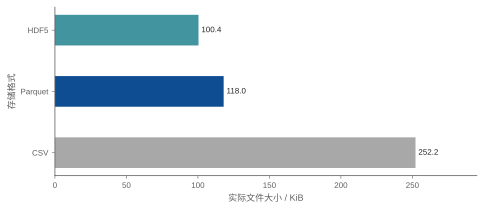

dataset / chunks / subset: (30, 12, 3) (1, 12, 3) (10, 4, 3)
units: angstrom
    format         KiB
0      CSV  252.172852
1  Parquet  118.004883
2     HDF5  100.423828


In [3]:
values = rng.normal(size=(1600, 8))
frame = pd.DataFrame(values, columns=[f"f{i}" for i in range(8)])
with tempfile.TemporaryDirectory() as tmp:
    root = Path(tmp)
    frame.to_csv(root / "array.csv", index=False, float_format="%.17g")
    frame.to_parquet(root / "array.parquet", index=False, compression="zstd")
    with h5py.File(root / "array.h5", "w") as file:
        file.create_dataset("values", data=values, chunks=(100, 8), compression="gzip")
    names = ["CSV", "Parquet", "HDF5"]
    sizes = [
        (root / name).stat().st_size / 1024 for name in ["array.csv", "array.parquet", "array.h5"]
    ]
fig, ax = plt.subplots(figsize=(6.8, 3.0))
ax.barh(names, sizes, color=[GRAY, BLUE, AQUA], height=0.5)
ax.set(xlabel="实际文件大小 / KiB", ylabel="存储格式")
for i, size in enumerate(sizes):
    ax.text(size + 2, i, f"{size:.1f}", va="center", fontsize=8)
ax.set_xlim(0, max(sizes) * 1.17)
fig.tight_layout()
plt.show()

positions = rng.normal(size=(30, 12, 3))
with tempfile.TemporaryDirectory() as tmp:
    with h5py.File(Path(tmp) / "trajectory.h5", "w") as file:
        ds = file.create_dataset("positions", data=positions, chunks=(1, 12, 3), compression="gzip")
        ds.attrs["units"] = "angstrom"
        selected = ds[::3, :4, :]
        print("dataset / chunks / subset:", ds.shape, ds.chunks, selected.shape)
        print("units:", ds.attrs["units"])
        assert np.array_equal(selected, positions[::3, :4, :])
print(pd.DataFrame({"format": names, "KiB": sizes}))

读法：文件大小来自这组数据和压缩设置，不构成通用性能排名；HDF5 的逻辑切片通常按完整 chunk 解码，访问模式决定分块是否合适。

## 3. Parquet 列裁剪与谓词

构造带 row group 的表，读取少量列并筛选帧号。比较逻辑结果，而不把小文件的计时当作格式结论。

In [4]:
with tempfile.TemporaryDirectory() as tmp:
    table = pd.DataFrame(
        {
            "frame": np.arange(600),
            "energy": rng.normal(size=600),
            "batch": np.repeat(["A", "B", "C"], 200),
        }
    )
    path = Path(tmp) / "observations.parquet"
    pq.write_table(pa.Table.from_pandas(table, preserve_index=False), path, row_group_size=100)
    result = pq.read_table(
        path, columns=["frame", "energy"], filters=[("frame", ">=", 550)]
    ).to_pandas()
    print("row groups:", pq.ParquetFile(path).num_row_groups)
    print("返回形状:", result.shape, "列:", result.columns.tolist())
    assert np.array_equal(result.frame.to_numpy(), np.arange(550, 600))

row groups: 6
返回形状: (50, 2) 列: ['frame', 'energy']


读法：列裁剪减少读取的字段；能否跳过 row group 还取决于统计信息、排序和过滤表达式。压缩后的 Parquet 不是可以直接零拷贝映射的原始 ndarray。

## 4. SQL：关联、聚合与窗口

用 SQLite 的内存数据库组织运行与帧，建立键约束；对同一轨迹求均值，并保留逐帧结果计算差分。

In [5]:
with sqlite3.connect(":memory:") as con:
    con.execute("PRAGMA foreign_keys=ON")
    con.execute("CREATE TABLE runs (run_id TEXT PRIMARY KEY, temperature REAL NOT NULL)")
    con.execute(
        """CREATE TABLE frames (
run_id TEXT, step INTEGER, energy REAL,
PRIMARY KEY(run_id,step),
FOREIGN KEY(run_id) REFERENCES runs(run_id))"""
    )
    con.executemany("INSERT INTO runs VALUES (?,?)", [("A", 300.0), ("B", 600.0)])
    con.executemany(
        "INSERT INTO frames VALUES (?,?,?)",
        [("A", 0, -2.0), ("A", 1, -1.8), ("A", 2, -1.9), ("B", 0, -1.0), ("B", 1, -0.8)],
    )
    print(
        pd.read_sql_query(
            """SELECT r.run_id, temperature, AVG(energy) AS mean_energy
FROM runs r JOIN frames f ON r.run_id=f.run_id
GROUP BY r.run_id, temperature""",
            con,
        )
    )
    print(
        pd.read_sql_query(
            """SELECT run_id,step,energy,
energy-LAG(energy) OVER(PARTITION BY run_id ORDER BY step) AS delta
FROM frames ORDER BY run_id,step""",
            con,
        )
    )

  run_id  temperature  mean_energy
0      A        300.0         -1.9
1      B        600.0         -0.9
  run_id  step  energy  delta
0      A     0    -2.0    NaN
1      A     1    -1.8    0.2
2      A     2    -1.9   -0.1
3      B     0    -1.0    NaN
4      B     1    -0.8    0.2


读法：GROUP BY 改变行粒度，窗口函数保留原行并指定组内顺序。轨迹边界通过 PARTITION BY 明确隔离，避免把不同运行的首尾帧相减。

## 5. extxyz、ASE database 与 LMDB 事务

只使用合成 Si 二聚体，检查结构、能量、力的往返；再用 LMDB 的读快照观察事务隔离。

In [6]:
atoms = Atoms("Si2", positions=[[0, 0, 0], [2.3, 0, 0]], cell=[6, 6, 6], pbc=True)
forces = np.array([[0.1, 0, 0], [-0.1, 0, 0]])
atoms.calc = SinglePointCalculator(atoms, energy=-1.2, forces=forces)
with tempfile.TemporaryDirectory() as tmp:
    root = Path(tmp)
    write(root / "frame.extxyz", atoms)
    restored = read(root / "frame.extxyz")
    db = connect(root / "structures.db")
    key = db.write(atoms, frame_index=0, label="synthetic")
    row = db.get(id=key)
    print(
        "extxyz 能量与力往返:",
        restored.get_potential_energy(),
        np.allclose(restored.get_forces(), forces),
    )
    print("ASE 数据库原子数/能量:", row.natoms, row.energy)
    env = lmdb.open(str(root / "records"), map_size=10_000_000)
    with env.begin(write=True) as txn:
        txn.put(b"version", b"1")
    with env.begin() as old:
        with env.begin(write=True) as txn:
            txn.put(b"version", b"2")
        print("旧事务仍读取:", old.get(b"version"))
        assert old.get(b"version") == b"1"
    with env.begin() as current:
        print("新事务读取:", current.get(b"version"))
        assert current.get(b"version") == b"2"
    env.close()
    assert np.allclose(restored.positions, atoms.positions)

extxyz 能量与力往返: -1.2 True
ASE 数据库原子数/能量: 2 -1.2
旧事务仍读取: b'1'
新事务读取: b'2'


读法：结构格式保留对象语义，数据库增加可查询元数据；LMDB 只提供字节键值与事务，记录的 dtype、shape、单位和版本仍需应用定义。

## 小结

schema 说明数据是什么，布局决定读取什么便宜，查询定义观测粒度，事务定义更新的可见边界。文件体积只是一个指标；可靠的数据层还需要往返验证、稳定键、单位和来源记录。